# What separates winning performances in the NBA?

**Question.** A coaching staff has limited practice time. Of the four things a team controls in a game,
**shooting efficiency, turnovers, offensive rebounding and getting to the free-throw line**, which matters most
for winning, and has the 3-point revolution changed the answer?

These are Dean Oliver's *Four Factors*, the standard framework in basketball analytics. Oliver proposed rough
weights of 40% / 25% / 20% / 15%. This notebook measures them on 23 complete seasons of real games.

**Data.** Team box scores for regular-season games from the Kaggle dataset *Historical NBA Data and Player Box
Scores* by Eoin A Moore, pinned to version 552. Run `python download_data.py` first. A completeness check below
finds two seasons the source is missing games for (2000-01 has half its games, 2021-22 has one) and excludes
them, leaving **23 complete seasons, 2001-02 to 2024-25**.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, roc_auc_score

FIG = Path('figures'); FIG.mkdir(exist_ok=True)
BLUE, ORANGE, AQUA, YELLOW, GREY, INK = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#9a9993', '#0b0b0b'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e4e3df', 'axes.axisbelow': True,
                     'axes.titlelocation': 'left', 'axes.titlesize': 12, 'font.size': 10})

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=150, bbox_inches='tight'); plt.show()

raw = pd.read_csv('data/TeamStatistics.csv', low_memory=False)
raw['date'] = pd.to_datetime(raw['gameDateTimeEst'], utc=True)
# An NBA season starts in October: 2024-25 is labelled 2024
raw['season'] = np.where(raw['date'].dt.month >= 8, raw['date'].dt.year, raw['date'].dt.year - 1)
games = raw[(raw['gameType'] == 'Regular Season') & raw['season'].between(2000, 2024)].copy()

# Completeness check: a full season has 1,189-1,230 games; the shortest real ones here (COVID 2019-20,
# lockout 2011-12) have 979-990.
# Anything far below that is missing data in the source, not real basketball.
per_season = games.groupby('season')['gameId'].nunique()
incomplete = per_season[per_season < 900]
print('Games per season:', per_season.to_dict())
print('Dropped as incomplete in the source data:', {f'{s}-{str(s + 1)[2:]}': n for s, n in incomplete.items()})
games = games[~games['season'].isin(incomplete.index)]
print(f"{len(games):,} team-game rows, {games['gameId'].nunique():,} games, {games['season'].nunique()} seasons")
print('Rows per game:', games.groupby('gameId').size().value_counts().to_dict())

/home/linked/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Games per season: {2000: 592, 2001: 1189, 2002: 1189, 2003: 1189, 2004: 1230, 2005: 1230, 2006: 1230, 2007: 1230, 2008: 1230, 2009: 1230, 2010: 1230, 2011: 990, 2012: 1229, 2013: 1230, 2014: 1230, 2015: 1230, 2016: 1230, 2017: 1230, 2018: 1230, 2019: 979, 2020: 1160, 2021: 1, 2022: 1230, 2023: 1230, 2024: 1226}
Dropped as incomplete in the source data: {'2000-01': 592, '2021-22': 1}
55,202 team-game rows, 27,601 games, 23 seasons
Rows per game: {2: 27601}


## 1. Compute the Four Factors for both teams in every game

| Factor | Formula | Measures |
|---|---|---|
| eFG% | (FGM + 0.5 × 3PM) / FGA | Shooting, with 3-pointers worth 1.5 two-pointers |
| TOV% | TOV / (FGA + 0.44 × FTA + TOV) | Turnovers per possession (lower is better) |
| ORB% | ORB / (ORB + opponent DRB) | Share of your own misses you rebound |
| FT rate | FTM / FGA | Free throws made per shot attempt |

Each game appears twice (once per team), so each row is joined to its opponent's row.

In [2]:
cols = ['gameId', 'teamId', 'fieldGoalsMade', 'fieldGoalsAttempted', 'threePointersMade', 'threePointersAttempted',
        'turnovers', 'freeThrowsAttempted', 'freeThrowsMade', 'reboundsOffensive', 'reboundsDefensive']
both = games.merge(games[cols], on='gameId', suffixes=('', '_opp'))
both = both[both['teamId'] != both['teamId_opp']].copy()

def factors(d, s=''):
    return pd.DataFrame({
        'efg': (d['fieldGoalsMade' + s] + 0.5 * d['threePointersMade' + s]) / d['fieldGoalsAttempted' + s],
        'tov': d['turnovers' + s] / (d['fieldGoalsAttempted' + s] + 0.44 * d['freeThrowsAttempted' + s] + d['turnovers' + s]),
        'ftr': d['freeThrowsMade' + s] / d['fieldGoalsAttempted' + s],
    })

own, opp = factors(both), factors(both, '_opp')
both['orb'] = both['reboundsOffensive'] / (both['reboundsOffensive'] + both['reboundsDefensive_opp'])
both['orb_opp'] = both['reboundsOffensive_opp'] / (both['reboundsOffensive_opp'] + both['reboundsDefensive'])
FACTORS = ['efg', 'tov', 'orb', 'ftr']
LABELS = {'efg': 'Shooting (eFG%)', 'tov': 'Turnovers (TOV%)', 'orb': 'Off. rebounding (ORB%)', 'ftr': 'Free throws (FT rate)'}
for f in ['efg', 'tov', 'ftr']:
    both[f], both[f + '_opp'] = own[f], opp[f]
for f in FACTORS:
    both['diff_' + f] = both[f] - both[f + '_opp']
both['win'] = both['win'].astype(int)

# Keep one row per game (the home team's view) so no game is counted twice
home = both[both['home'] == 1].copy()
print(f"{len(home):,} games; missing factor values: {home[['diff_' + f for f in FACTORS]].isna().sum().sum()}")
print(f"Home teams won {home['win'].mean():.1%} of games")
home[['diff_' + f for f in FACTORS]].describe().round(3)

27,601 games; missing factor values: 0
Home teams won 58.7% of games


,diff_efg,diff_tov,diff_orb,diff_ftr
count,27601.000,27601.000,27601.000,27601.000
mean,0.012,-0.003,0.011,0.009
std,0.090,0.047,0.107,0.109
min,-0.397,-0.197,-0.418,-0.524
25%,-0.048,-0.034,-0.062,-0.061
50%,0.012,-0.003,0.011,0.009
75%,0.072,0.029,0.082,0.079
max,0.359,0.198,0.432,0.603


## 2. How often does the team that wins each factor win the game?

In [3]:
win_rate = {}
for f in FACTORS:
    better = home['diff_' + f] < 0 if f == 'tov' else home['diff_' + f] > 0   # fewer turnovers is better
    # From the home team's view: share of games won by whichever team was better at this factor
    win_rate[f] = (home.loc[better, 'win'].sum() + (1 - home.loc[~better, 'win']).sum()) / len(home) * 100
win_rate = pd.Series(win_rate).rename(LABELS).round(1)
win_rate

Shooting (eFG%)           80.9
Turnovers (TOV%)          56.3
Off. rebounding (ORB%)    56.4
Free throws (FT rate)     59.9
dtype: float64

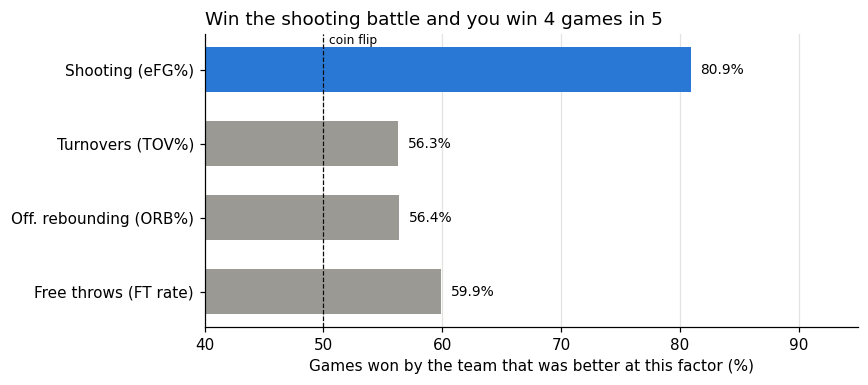

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(win_rate.index[::-1], win_rate.values[::-1], color=[GREY, GREY, GREY, BLUE], height=0.6)
ax.axvline(50, color=INK, lw=0.8, ls='--'); ax.text(50.5, 3.35, 'coin flip', fontsize=8)
for y, v in enumerate(win_rate.values[::-1]):
    ax.text(v + 0.8, y, f'{v:.1f}%', va='center', fontsize=9)
ax.set_xlim(40, 95); ax.set_xlabel('Games won by the team that was better at this factor (%)')
ax.set_title('Win the shooting battle and you win 4 games in 5'); ax.grid(axis='y', visible=False)
save(fig, '01_factor_win_rates.png')

## 3. How much does each factor matter, holding the others equal?

A logistic regression of *win* on the four factor gaps (each standardised, so a one-unit change means
"one standard deviation better than the opponent") gives each factor's weight while holding the others fixed.

**Fair test:** the model is trained on 2001-02 to 2019-20 and evaluated on the later seasons it never saw
(2020-21 and 2022-23 to 2024-25; 2021-22 is missing from the source).
These are statistics *from* the game, so this explains what separates winners from losers. It is not a
pre-game prediction.

In [5]:
X = ['diff_' + f for f in FACTORS]
train, test = home[home['season'] <= 2019], home[home['season'] >= 2020]
scaler = StandardScaler().fit(train[X])
model = LogisticRegression().fit(scaler.transform(train[X]), train['win'])
prob = model.predict_proba(scaler.transform(test[X]))[:, 1]
print(f"Trained on {len(train):,} games, tested on {len(test):,} unseen games from {test['season'].nunique()} later seasons")
print(f"Accuracy: {accuracy_score(test['win'], prob > 0.5):.1%}   AUC: {roc_auc_score(test['win'], prob):.3f}")
coef = pd.Series(model.coef_[0], index=[LABELS[f] for f in FACTORS])
weights = (coef.abs() / coef.abs().sum() * 100).round(1)
pd.DataFrame({'coefficient (per 1 SD)': coef.round(2), 'relative weight %': weights,
              "Oliver's estimate %": [40, 25, 20, 15]})

Trained on 22,755 games, tested on 4,846 unseen games from 4 later seasons
Accuracy: 95.4%   AUC: 0.993


,coefficient (per 1 SD),relative weight %,Oliver's estimate %
Shooting (eFG%),8.74,46.6,40
Turnovers (TOV%),-4.21,22.5,25
Off. rebounding (ORB%),3.19,17.0,20
Free throws (FT rate),2.63,14.0,15


## 4. Has the 3-point era changed the weights?

In [6]:
three_share = games.groupby('season').apply(lambda g: g['threePointersAttempted'].sum() / g['fieldGoalsAttempted'].sum() * 100)

def era_weights(lo, hi):
    s = home[home['season'].between(lo, hi)]
    m = LogisticRegression().fit(StandardScaler().fit_transform(s[X]), s['win'])
    w = np.abs(m.coef_[0]); return pd.Series(w / w.sum() * 100, index=[LABELS[f] for f in FACTORS])

eras = pd.DataFrame({'2001-02 to 2011-12': era_weights(2001, 2011), '2013-14 to 2024-25': era_weights(2013, 2024)}).round(1)
print(f"3-pointers as a share of all shots: {three_share.loc[2001]:.0f}% in 2001-02 -> {three_share.loc[2024]:.0f}% in 2024-25")
eras

3-pointers as a share of all shots: 18% in 2001-02 -> 42% in 2024-25


,2001-02 to 2011-12,2013-14 to 2024-25
Shooting (eFG%),45.6,48.3
Turnovers (TOV%),22.5,22.3
Off. rebounding (ORB%),17.0,17.1
Free throws (FT rate),14.8,12.3


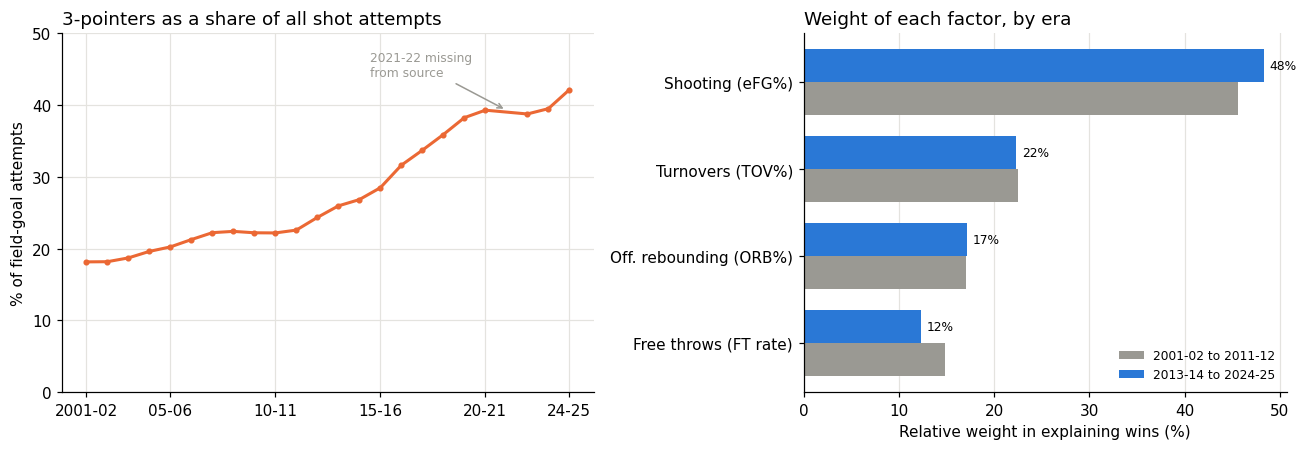

In [7]:
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={'width_ratios': [1.1, 1]})
a.plot(three_share.index, three_share.values, color=ORANGE, lw=2, marker='o', ms=3)
a.annotate('2021-22 missing\nfrom source', (2021, three_share.loc[2020]), xytext=(2014.5, 44), fontsize=8, color=GREY, arrowprops=dict(arrowstyle='->', color=GREY))
a.set_title('3-pointers as a share of all shot attempts'); a.set_ylabel('% of field-goal attempts'); a.set_ylim(0, 50)
a.set_xticks([2001, 2005, 2010, 2015, 2020, 2024], ['2001-02', '05-06', '10-11', '15-16', '20-21', '24-25'])
y = np.arange(len(eras)); h = 0.38
b.barh(y + h / 2, eras.iloc[:, 0], h, color=GREY, label=eras.columns[0])
b.barh(y - h / 2, eras.iloc[:, 1], h, color=BLUE, label=eras.columns[1])
for i in range(len(eras)):
    b.text(eras.iloc[i, 1] + 0.6, i - h / 2, f'{eras.iloc[i, 1]:.0f}%', va='center', fontsize=8)
b.set_yticks(y, eras.index); b.invert_yaxis(); b.set_xlabel('Relative weight in explaining wins (%)')
b.set_title('Weight of each factor, by era'); b.legend(frameon=False, loc='lower right', fontsize=8); b.grid(axis='y', visible=False)
save(fig, '02_three_point_era.png')

## 5. Findings and recommendations

**Findings** (numbers printed above):
1. **Shooting efficiency decides most games.** The team with the better eFG% won about 81% of games; being better
   at any other single factor wins only 56-60%, little better than a coin flip on its own.
2. **The weights are close to Oliver's 40/25/20/15**: shooting carries nearly half of the explanatory weight,
   turnovers about a fifth, offensive rebounding and free throws the rest.
3. **Four numbers explain almost every result.** A model trained only on games up to 2019-20 classified about 95%
   of the later, unseen games correctly from the four factor gaps.
4. **The 3-point revolution moved the weights only slightly.** 3-pointers went from under a fifth of all shots to over
   two-fifths, yet shooting's share of the weight rose by only a few points and free throws' share fell a little.

**For a coaching staff:**
- Spend the most time on **shot quality**, both taking good shots and forcing opponents into bad ones. A defensive
  stop on a 3-point attempt is worth as much as improving your own shooting.
- **Turnovers are the second lever**, worth roughly half as much as shooting; ball security still pays.
- Offensive rebounding and drawing fouls matter, but chasing them at the cost of transition defence or shot
  selection is a poor trade.

**Limitations.** Team-level box scores only (no lineups or shot locations); the factors are measured in the same game
they explain, so the model describes winning, it does not forecast it; regular season only; 2000-01 and 2021-22 are
incomplete in the source data and excluded.